In [89]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [90]:
df = pd.read_csv('train.csv')

In [91]:
df.head(5)

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [92]:
df.shape

(404290, 6)

In [93]:
df.sample(10)

,id,qid1,qid2,question1,question2,is_duplicate
283368,283368,154186,325279,Which language is more useful to learn - Germa...,Should I learn French or Spanish?,0
297774,297774,420172,420173,What are some inspirational books for students?,Which are the most inspirational books for stu...,1
43392,43392,78056,78057,I didn't turned the back up messege option in ...,What the cheapest way ship personal items back...,0
358337,358337,487802,487803,Will I get into Lady Hardinge Medical College ...,How good is the Lady Hardinge Medical College?...,0
173261,173261,267320,222675,How do people who suddenly become rich handle ...,How do rich people avoid friends who ask for m...,1
360500,360500,31808,116123,How can we increase confidence?,How can I increase my confidence?,1
24903,24903,46465,46466,How do I know am not been cheated on by my par...,How will you know if your partner was or still...,1
96286,96286,160407,160408,How do element atoms bond to form a compound m...,How do atoms join together to form molecules?,0
250640,250640,364590,364591,What lens should I go for: Nikon 35mm 1.8g or ...,I have a Nikon D5300 18-55mm+70-300mm vr. I wa...,0
75407,75407,129065,129066,Are all five Trump kids going to have Secret S...,Will Donald Trump's adult children receive Sec...,1


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404290 entries, 0 to 404289
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            404290 non-null  int64 
 1   qid1          404290 non-null  int64 
 2   qid2          404290 non-null  int64 
 3   question1     404289 non-null  object
 4   question2     404288 non-null  object
 5   is_duplicate  404290 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 18.5+ MB


In [95]:
# missing values
df.isnull().sum()

id              0
qid1            0
qid2            0
question1       1
question2       2
is_duplicate    0
dtype: int64

In [96]:
df = df.dropna()

In [97]:
# missing values
df.isnull().sum()

id              0
qid1            0
qid2            0
question1       0
question2       0
is_duplicate    0
dtype: int64

In [98]:
# Duplicate rows
df.duplicated().sum()

# The data does not contain duplicate values.

np.int64(0)

### Distribution of duplicate and non-duplicate question 

In [99]:
df['is_duplicate'].value_counts()

is_duplicate
0    255024
1    149263
Name: count, dtype: int64

In [100]:
(df['is_duplicate'].value_counts()/df['is_duplicate'].count())*100

is_duplicate
0    63.079941
1    36.920059
Name: count, dtype: float64

<Axes: xlabel='is_duplicate'>

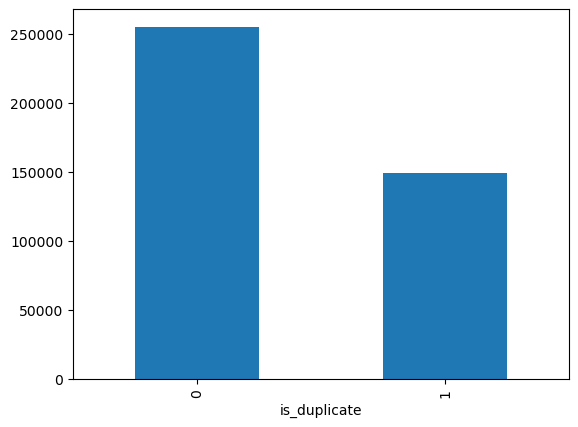

In [101]:
df['is_duplicate'].value_counts().plot(kind = 'bar')

# The dataset is slightly imbalanced; it is skewed towards one class—specifically, the '0th' class.

### Repeated question

In [102]:
df['qid1'].value_counts()

qid1
8461      50
14110     48
25984     47
20628     47
1749      47
          ..
537924     1
537926     1
537928     1
537930     1
537932     1
Name: count, Length: 290652, dtype: int64

In [103]:
df['question1'].value_counts()

question1
How do I improve my English speaking?                                                         50
How does the ban on 500 and 1000 rupee notes helps to identify black money and corruption?    48
How do I improve my English language?                                                         47
How can changing 500 and 1000 rupee notes end the black money in India?                       47
What should I do to earn money online?                                                        47
                                                                                              ..
What happens if you put milk in a coffee maker?                                                1
Does Stalin have any grandchildren that are still alive and are they pro-Russia?               1
What is the difference between who and how?                                                    1
How do you diagnose antisocial personality disorder?                                           1
What is the step by 

In [104]:
pd.Series(df['qid1'].tolist() + df['qid2'].tolist()).shape[0]
# Totle question 
# This is the question where the question is being asked again.

808574

In [105]:
# Combine all question IDs from both columns into a single pandas Series to fetch the unique questionID

qid = pd.Series(df['qid1'].tolist() + df['qid2'].tolist())
print("Number of unique question", np.unique(qid).shape[0])

x = qid.value_counts()>1
print("Number of question gettig repeated", x[x].shape[0])

Number of unique question 537929
Number of question gettig repeated 111778


In [106]:
qid = pd.Series(df['qid1'].tolist() + df['qid2'].tolist())
qid.value_counts().values


array([157, 120, 111, ...,   1,   1,   1])

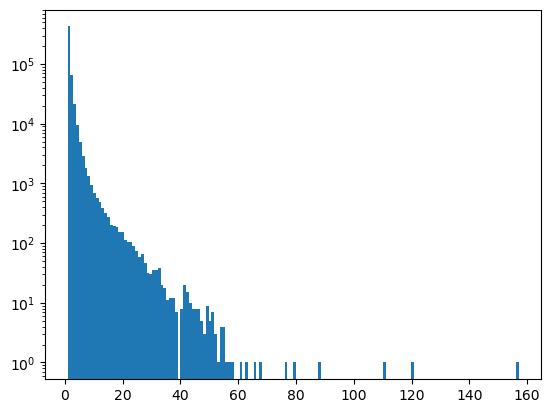

In [107]:
# repeated question histogram
plt.hist(qid.value_counts().values, bins=160)
plt.yscale('log')
plt.show()

### One issue is that the dataset is very large, so I decided to randomly select 30,000 rows of data.

In [108]:
new_df = df.sample(30000)
new_df

,id,qid1,qid2,question1,question2,is_duplicate
377821,377821,509159,509160,What would be more relevant and beneficial for...,What is CASA SME CIM wheel in Manufacturing En...,0
135444,135444,60930,77758,Where can I get very friendly assistance in Sy...,Where can I get very friendly assistance in pr...,1
127314,127314,204994,204995,How do I know whether my phone has LTE/4G supp...,Does an 800 MHz LTE phone support 850 MHz band...,0
358749,358749,412935,43796,Is it really possible to increase penis size a...,Can the penis size (length or girth) be perman...,0
311236,311236,435484,435485,How can I make money with Facebook traffic?,How do you make money on facebook?,1
...,...,...,...,...,...,...
388117,388117,520484,520485,Who are the moonies?,Why are there still Moonies?,0
229860,229860,339261,339262,What was the best one minute of your life?,Which was the best minute of your life?,0
108085,108085,177664,177665,What are the first or must-have homebrew packa...,Can I Install Mac OS on my Acer Laptop?,0
346183,346183,474537,223667,"What is the nearest airport to Daytona Beach, ...","What is the nearest airport to Daytona Beach, ...",0


In [109]:
new_df.isnull().sum()

id              0
qid1            0
qid2            0
question1       0
question2       0
is_duplicate    0
dtype: int64

In [110]:
new_df.duplicated().sum()

np.int64(0)

In [111]:
# Features (X): 'question1' and 'question2' (to be transformed using Bag of Words vectors)
ques_df = new_df[['question1', 'question2']]
ques_df.head(4)

,question1,question2
377821,What would be more relevant and beneficial for...,What is CASA SME CIM wheel in Manufacturing En...
135444,Where can I get very friendly assistance in Sy...,Where can I get very friendly assistance in pr...
127314,How do I know whether my phone has LTE/4G supp...,Does an 800 MHz LTE phone support 850 MHz band...
358749,Is it really possible to increase penis size a...,Can the penis size (length or girth) be perman...


In [112]:
question = list(new_df['question1']) + list(new_df['question2'])

len(question)

60000

In [113]:
from sklearn.feature_extraction.text import CountVectorizer
# create object of CountVectorizer
cv = CountVectorizer(max_features = 3000)

# Marge text:
question = list(new_df['question1']) + list(new_df['question2'])
q1_arr, q2_arr = np.vsplit(cv.fit_transform(question).toarray(),2)
q1_arr

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [114]:
q1_arr.shape[0]

30000

In [115]:
# see the Vocabulary (Features) learned by CountVectorizer

features_name = cv.get_feature_names_out()

In [116]:
features_name.shape

(3000,)

In [117]:
features_name.tolist()

['000',
 '10',
 '100',
 '1000',
 '10000',
 '10k',
 '10th',
 '11',
 '11th',
 '12',
 '12th',
 '13',
 '14',
 '15',
 '15000',
 '15k',
 '16',
 '17',
 '18',
 '19',
 '1st',
 '20',
 '200',
 '2000',
 '2012',
 '2013',
 '2014',
 '2015',
 '2016',
 '2017',
 '2018',
 '2020',
 '21',
 '22',
 '23',
 '24',
 '25',
 '29',
 '2nd',
 '30',
 '300',
 '30k',
 '32',
 '35',
 '3d',
 '3g',
 '3rd',
 '40',
 '400',
 '4g',
 '50',
 '500',
 '5s',
 '5th',
 '60',
 '6s',
 '70',
 '80',
 '90',
 '99',
 'ability',
 'able',
 'about',
 'above',
 'abroad',
 'absolute',
 'abuse',
 'ac',
 'academic',
 'accent',
 'accenture',
 'accept',
 'accepted',
 'access',
 'accidentally',
 'according',
 'account',
 'accountant',
 'accounting',
 'accounts',
 'accurate',
 'achieve',
 'acid',
 'acne',
 'across',
 'act',
 'acting',
 'action',
 'active',
 'activities',
 'activity',
 'actor',
 'actors',
 'actress',
 'actresses',
 'actual',
 'actually',
 'ad',
 'adam',
 'add',
 'added',
 'addiction',
 'address',
 'administration',
 'admission',
 'adobe

In [118]:
temp_df1 = pd.DataFrame(q1_arr, index = ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index = ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis = 1)

In [119]:
temp_df.head(3)

,0,1,2,3,4,5,6,7,8,9,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
377821,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
135444,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
127314,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [120]:
temp_df.shape

(30000, 6000)

In [121]:
temp_df['is_duplicate'] = new_df['is_duplicate']

In [122]:
temp_df

,0,1,2,3,4,5,6,7,8,9,...,2991,2992,2993,2994,2995,2996,2997,2998,2999,is_duplicate
377821,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
135444,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
127314,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
358749,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
311236,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
388117,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
229860,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
108085,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
346183,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [123]:
new_df

,id,qid1,qid2,question1,question2,is_duplicate
377821,377821,509159,509160,What would be more relevant and beneficial for...,What is CASA SME CIM wheel in Manufacturing En...,0
135444,135444,60930,77758,Where can I get very friendly assistance in Sy...,Where can I get very friendly assistance in pr...,1
127314,127314,204994,204995,How do I know whether my phone has LTE/4G supp...,Does an 800 MHz LTE phone support 850 MHz band...,0
358749,358749,412935,43796,Is it really possible to increase penis size a...,Can the penis size (length or girth) be perman...,0
311236,311236,435484,435485,How can I make money with Facebook traffic?,How do you make money on facebook?,1
...,...,...,...,...,...,...
388117,388117,520484,520485,Who are the moonies?,Why are there still Moonies?,0
229860,229860,339261,339262,What was the best one minute of your life?,Which was the best minute of your life?,0
108085,108085,177664,177665,What are the first or must-have homebrew packa...,Can I Install Mac OS on my Acer Laptop?,0
346183,346183,474537,223667,"What is the nearest airport to Daytona Beach, ...","What is the nearest airport to Daytona Beach, ...",0


###  Fit the model to the training data:

In [124]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(temp_df.iloc[:, 0:-1].values, temp_df.iloc[:, -1].values, test_size=0.2, random_state = 1)

In [125]:
X_train

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [126]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier()

rf.fit(X_train, y_train) 

RandomForestClassifier()

In [127]:
y_pred = rf.predict(X_test) 
accuracy_score(y_test, y_pred)

0.7405

In [135]:
from xgboost import XGBClassifier
xgb = XGBClassifier()

xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [136]:
y_pred = xgb.predict(X_test) 
accuracy_score(y_test, y_pred)

0.7301666666666666

rendomForest and xbgboost se around 74% ka accuracy mil rha hai, bethout any do it apply any kind of preproccesing and feature selection or feature engineering kiye bina 

In [ ]:
1. q1_lenth -> char lenth of q1
2. q2_lenth -> char lenth of q2
3. q1_words -> words in q1
4. q2_words -> words in q2
5. words comman -> comman and unique words
6. words total -> Total words in q1 + Total words in q2
7. words share -> words common / words total